<a href="https://colab.research.google.com/github/MarokoVo/Data-analytics/blob/main/lab3/lab3_models_development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("auto_cleaned.csv")

train = df.sample(frac=0.8, random_state=42)
test = df.drop(train.index)
print(len(train), len(test))

164 41


In [9]:
results = []
def evaluate(name, y_train, pred_train, y_test, pred_test):
    results.append({
        "Модель": name,
        "R² навчання": r2_score(y_train, pred_train),
        "MSE навчання": mean_squared_error(y_train, pred_train),
        "R² тест": r2_score(y_test, pred_test),
        "MSE тест": mean_squared_error(y_test, pred_test)})

Завдання 1

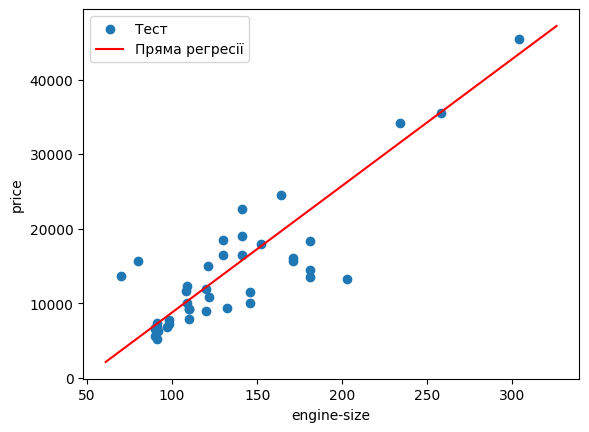

,Модель,R² навчання,MSE навчання,R² тест,MSE тест
0,Проста (engine-size),0.750919,1.474635e+07,0.70403,2.083732e+07


In [10]:
model1 = Polynomial.fit(train["engine-size"], train["price"], deg=1)
pred_train1 = model1(train["engine-size"])
pred_test1 = model1(test["engine-size"])
evaluate("Проста (engine-size)", train["price"], pred_train1, test["price"], pred_test1)

x_line = np.linspace(df["engine-size"].min(), df["engine-size"].max(), 100)
plt.scatter(test["engine-size"], test["price"], label="Тест")
plt.plot(x_line, model1(x_line), color="red", label="Пряма регресії")
plt.xlabel("engine-size"); plt.ylabel("price"); plt.legend(); plt.show()

pd.DataFrame(results)

Висновок: R² на тесті 0,704 і MSE 2,08·10⁷. engine-size пояснює приблизно 70% розкиду цін, це хороша якість для однієї ознаки. Тестова MSE трохи більша за навчальну (1,47·10⁷)

Завдання 2

In [11]:
features2 = ["normalized-losses", "highway-mpg"]
model2 = LinearRegression()
model2.fit(train[features2], train["price"])
pred_train2 = model2.predict(train[features2])
pred_test2 = model2.predict(test[features2])
evaluate("Множинна (normalized-losses, highway-mpg)", train["price"], pred_train2, test["price"], pred_test2)

print("Вільний член:", model2.intercept_, " Коефіцієнти:", model2.coef_)
pd.DataFrame(results)

Вільний член: 35962.07392286871  Коефіцієнти: [   5.64891625 -762.70712798]


,Модель,R² навчання,MSE навчання,R² тест,MSE тест
0,Проста (engine-size),0.750919,1.474635e+07,0.704030,2.083732e+07
1,"Множинна (normalized-losses, highway-mpg)",0.455905,3.221209e+07,0.539193,3.244238e+07


Висновак:Множинна модель із normalized-losses та highway-mpg гірша за просту: R² на тесті 0,539. Коефіцієнти: кожна додаткова миля на галон знижує прогнозовану ціну приблизно на 763, а ріст normalized-losses на одиницю додає лише близько 5,6. Ці дві ознаки пояснюють ціну гірше, ніж розмір двигуна. Те, що R² на тесті (0,539) трохи вищий за навчальний (0,456), пов'язано з тим, що тестова вибірка мала

Завдання 3

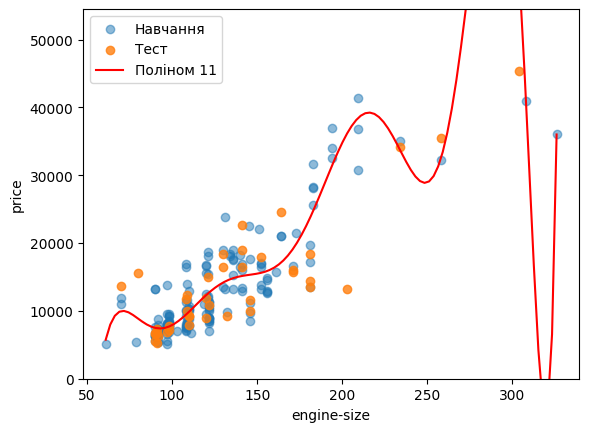

,Модель,R² навчання,MSE навчання,R² тест,MSE тест
0,Проста (engine-size),0.750919,1.474635e+07,0.704030,2.083732e+07
1,"Множинна (normalized-losses, highway-mpg)",0.455905,3.221209e+07,0.539193,3.244238e+07
2,Поліном 11 (engine-size),0.842574,9.320100e+06,0.542897,3.218164e+07


In [12]:
model3 = Polynomial.fit(train["engine-size"], train["price"], deg=11)
pred_train3 = model3(train["engine-size"])
pred_test3 = model3(test["engine-size"])
evaluate("Поліном 11 (engine-size)", train["price"], pred_train3, test["price"], pred_test3)

plt.scatter(train["engine-size"], train["price"], label="Навчання", alpha=0.5)
plt.scatter(test["engine-size"], test["price"], label="Тест", alpha=0.8)
plt.plot(x_line, model3(x_line), color="red", label="Поліном 11")
plt.ylim(0, df["price"].max() * 1.2)
plt.xlabel("engine-size"); plt.ylabel("price"); plt.legend(); plt.show()

pd.DataFrame(results)

Є ясні ознаки: на навчальних даних R² = 0,843 (найвище), а на тестових 0,543. Навчальна MSE (9,3·10⁶) приблизно в 3,5 рази менша за тестову (3,2·10⁷). На графіку крива хвилями підлаштовується під точки й різко падає та злітає на правому краю. Це перенавчання: модель запам'ятала навчальні дані й гірше працює на нових

Завдання 4

In [13]:
features4 = ["engine-size", "horsepower", "curb-weight", "highway-mpg"]
model4 = LinearRegression()
model4.fit(train[features4], train["price"])
pred_train4 = model4.predict(train[features4])
pred_test4 = model4.predict(test[features4])
evaluate("Множинна (4 ознаки)", train["price"], pred_train4, test["price"], pred_test4)

model5 = Polynomial.fit(train["engine-size"], train["price"], deg=3)
pred_train5 = model5(train["engine-size"])
pred_test5 = model5(test["engine-size"])
evaluate("Поліном 3 (engine-size)", train["price"], pred_train5, test["price"], pred_test5)

pd.DataFrame(results).round(3)

,Модель,R² навчання,MSE навчання,R² тест,MSE тест
0,Проста (engine-size),0.751,1.474635e+07,0.704,2.083732e+07
1,"Множинна (normalized-losses, highway-mpg)",0.456,3.221209e+07,0.539,3.244238e+07
2,Поліном 11 (engine-size),0.843,9.320100e+06,0.543,3.218164e+07
3,Множинна (4 ознаки),0.802,1.172318e+07,0.590,2.888588e+07
4,Поліном 3 (engine-size),0.796,1.205041e+07,0.631,2.596612e+07


Найкраща за тестом проста лінійна регресія (R² = 0,704, MSE = 2,08·10⁷). Складніші моделі (множинна, поліном 3, поліном 11) мають кращі показники на навчанні, але на тесті поступаються, тобто більша складність не дала кращого прогнозу.

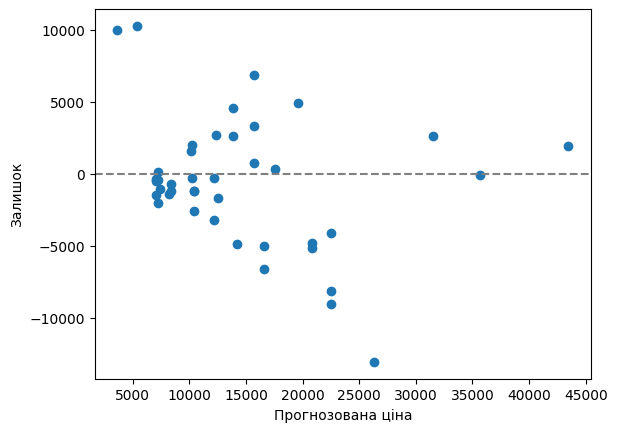

In [14]:
predicted = pred_test1
plt.scatter(predicted, test["price"] - predicted)
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Прогнозована ціна")
plt.ylabel("Залишок")
plt.show()